# Chess Move Prediction: Dataset Analysis (full run)
Data exploration for the next-move prediction project (`dataset.parquet`, one row per game).

**Task:** given both players' Elo and the moves played so far, predict the next move as a UCI string (e.g. `e2e4`). This is classification over roughly 1,900 move classes.

The notebook scans the file in parallel, one row group at a time, so memory stays bounded. With `STEP = 1` every game is read and all numbers are exact. Raise `STEP` for a quick sample. The scan result is cached to disk, so re-running the later cells doesn't rescan.

In [1]:
import os, pickle, time
from collections import Counter
from concurrent.futures import ProcessPoolExecutor, as_completed
from multiprocessing import get_context

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.compute as pc
import matplotlib.pyplot as plt

PATH = "dataset.parquet"            # run from the project folder, or give a full path
STEP = 1                            # read every STEP-th row group (1 = whole file)
N_WORKERS = os.cpu_count() or 1     # parallel processes for the scan
MAX_PLY = 60                        # per-ply statistics for the first MAX_PLY half-moves
USE_CACHE = True
CACHE = f"scan_cache_step{STEP}.pkl"

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "figure.dpi": 110, "axes.titlesize": 11,
})
print("workers:", N_WORKERS)

workers: 48


## 1. Schema and size

In [2]:
pf = pq.ParquetFile(PATH)
TOTAL_GAMES = pf.metadata.num_rows
print(f"games (exact): {TOTAL_GAMES:,}   row groups: {pf.num_row_groups:,}")
print(pf.schema_arrow.remove_metadata())

games (exact): 14,188,454   row groups: 14,189
date: string
white_elo: int64
black_elo: int64
end_type: string
winner: string
moves_san: list<element: string>
  child 0, element: string
moves_uci: list<element: string>
  child 0, element: string
moves_custom: list<element: string>
  child 0, element: string
source: string


## 2. Scan
Each worker handles a batch of row groups and returns:
- a small per-game table (source, Elo, outcome, length, year and a hash of the move list for duplicate detection),
- counts of every move,
- counts of every (ply, move) pair for the first `MAX_PLY` plies.

In [3]:
USE = ["date", "white_elo", "black_elo", "end_type", "winner", "source"]

def scan_chunk(idxs):
    f = pq.ParquetFile(PATH)
    frames, mv, pl, promo = [], Counter(), Counter(), 0
    for i in idxs:
        t = f.read_row_group(i, columns=USE + ["moves_uci"])
        mu = t["moves_uci"].combine_chunks()
        lens = pc.list_value_length(mu).to_numpy(zero_copy_only=False).astype(np.int64)
        flat = mu.flatten()

        vc = pc.value_counts(flat)
        mv.update(dict(zip(vc.field("values").to_pylist(), vc.field("counts").to_pylist())))
        promo += int(pc.sum(pc.equal(pc.utf8_length(flat), 5)).as_py() or 0)

        starts = np.cumsum(lens) - lens
        ply = np.arange(len(flat)) - np.repeat(starts, lens)
        keep = ply < MAX_PLY
        pair = pd.DataFrame({"ply": ply[keep],
                             "mv": flat.filter(pa.array(keep)).to_numpy(zero_copy_only=False)})
        pl.update(pair.value_counts().to_dict())

        df = t.drop_columns(["moves_uci", "date"]).to_pandas(strings_to_categorical=True)
        df["year"] = pd.to_numeric(t["date"].to_pandas().str[:4], errors="coerce").astype("float32")
        df["n_plies"] = lens.astype(np.int16)
        joined = pc.binary_join(mu, " ").to_numpy(zero_copy_only=False)
        df["h"] = pd.util.hash_array(joined)
        df["white_elo"] = df["white_elo"].astype("float32")
        df["black_elo"] = df["black_elo"].astype("float32")
        frames.append(df)
    return frames, mv, pl, promo

def concat_cat(frames):
    out = {}
    for c in frames[0].columns:
        cols = [fr[c] for fr in frames]
        out[c] = (pd.api.types.union_categoricals(cols) if isinstance(cols[0].dtype, pd.CategoricalDtype)
                  else np.concatenate([x.to_numpy() for x in cols]))
    return pd.DataFrame(out)

if USE_CACHE and os.path.exists(CACHE):
    games, move_counts, ply_counts, promo_total = pickle.load(open(CACHE, "rb"))
    print("loaded cache:", CACHE)
else:
    t0 = time.time()
    groups = list(range(0, pf.num_row_groups, STEP))
    n_chunks = max(1, min(len(groups), N_WORKERS * 8))
    chunks = [groups[k::n_chunks] for k in range(n_chunks)]
    frames, move_counts, ply_counts, promo_total = [], Counter(), Counter(), 0
    if N_WORKERS == 1:
        results = (scan_chunk(c) for c in chunks)
    else:
        ex = ProcessPoolExecutor(N_WORKERS, mp_context=get_context("fork"))
        results = (fu.result() for fu in as_completed([ex.submit(scan_chunk, c) for c in chunks]))
    for k, (fr, mv, pl, pr) in enumerate(results, 1):
        frames += fr; move_counts.update(mv); ply_counts.update(pl); promo_total += pr
        print(f"\rchunks {k}/{n_chunks}  {time.time()-t0:,.0f}s", end="")
    games = concat_cat(frames); del frames
    pickle.dump((games, move_counts, ply_counts, promo_total), open(CACHE, "wb"))
    print(f"\nscanned {len(games):,} games in {time.time()-t0:,.0f}s")

EXACT = (STEP == 1)
print(f"games in analysis: {len(games):,} ({len(games)/TOTAL_GAMES:.1%} of file){'' if EXACT else '  [SAMPLE]'}")
print(f"memory of per-game table: {games.memory_usage(deep=True).sum()/1e9:.2f} GB")
games.head()

loaded cache: scan_cache_step1.pkl
games in analysis: 14,188,454 (100.0% of file)
memory of per-game table: 0.35 GB


,white_elo,black_elo,end_type,winner,source,year,n_plies,h
0,2111.0,2242.0,resignation,black,PGNMentor,2001.0,82,2674560171273456682
1,2472.0,2384.0,resignation,white,LichessEliteDatabase,2021.0,85,8327011284024447023
2,2196.0,2118.0,resignation,white,LumbrasGigaBase,2011.0,85,7377513502563272155
3,2711.0,2700.0,resignation,black,LichessEliteDatabase,2023.0,84,2741235151480622864
4,1862.0,NaN,resignation,white,LumbrasGigaBase,2010.0,75,12660580034877487053


## 3. Sources, years and outcomes

                        games   share
source                               
LichessEliteDatabase  5525245  0.3894
LumbrasGigaBase       3701341  0.2609
PGNMentor             3431537  0.2419
TWIC                   858163  0.0605
Masters                322166  0.0227
LichessBroadcast       105329  0.0074
ChessOK                 62895  0.0044
Britbase                60148  0.0042
Kingbase                59317  0.0042
Convekta                37536  0.0026
ChessNostalgia          24592  0.0017
Chessopolis               123  0.0000
GamesOfGMs                 62  0.0000


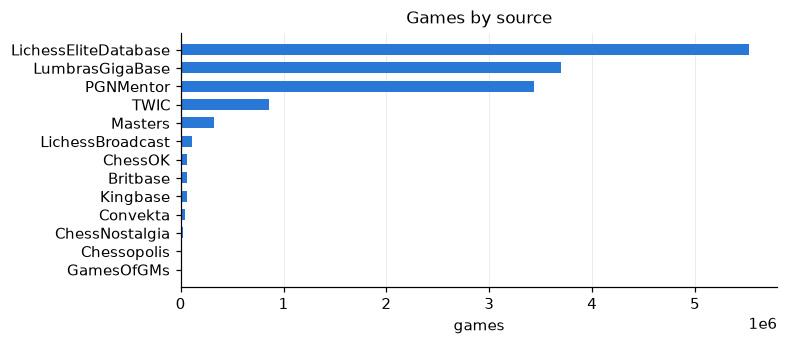

In [4]:
src = games["source"].value_counts()
print(pd.DataFrame({"games": src, "share": (src / len(games)).round(4)}).to_string())

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh([str(s) for s in src.index[::-1]], src.values[::-1], color=BLUE, height=0.6)
ax.set_title("Games by source"); ax.set_xlabel("games"); ax.grid(axis="y", visible=False)
plt.show()

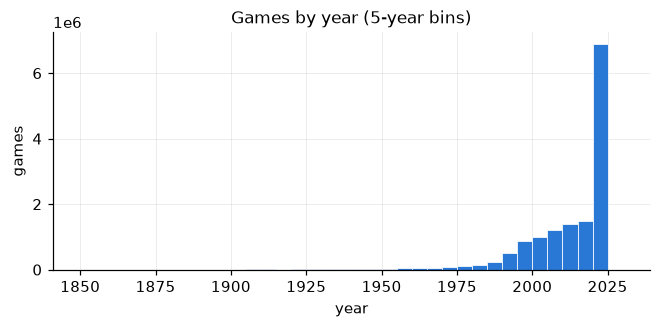

year missing/unknown: 0.00%   range: 1610.0 - 2024.0


In [5]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(games["year"].dropna(), bins=np.arange(1850, 2031, 5), color=BLUE, edgecolor="white", linewidth=0.5)
ax.set_title("Games by year (5-year bins)"); ax.set_xlabel("year"); ax.set_ylabel("games")
plt.show()
print("year missing/unknown:", f"{games['year'].isna().mean():.2%}",
      "  range:", games['year'].min(), "-", games['year'].max())

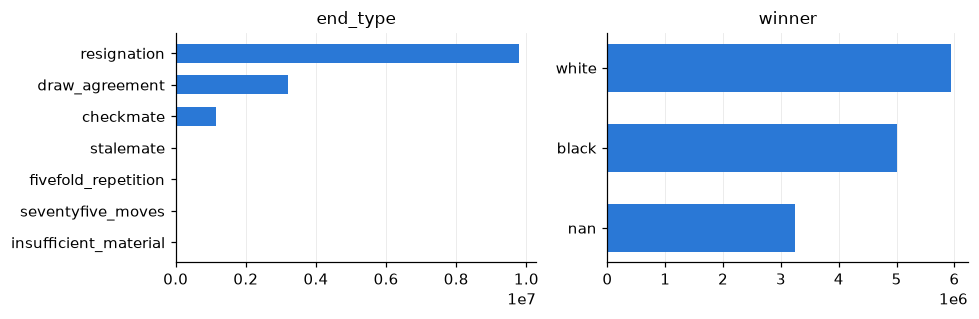

winner
white    0.418
black    0.353
NaN      0.228

end_type              resignation  draw_agreement  checkmate  fivefold_repetition  stalemate  seventyfive_moves  insufficient_material
source                                                                                                                                
PGNMentor                   0.666           0.288      0.044                0.000      0.002                0.0                    0.0
LichessEliteDatabase        0.713           0.147      0.134                0.001      0.006                0.0                    0.0
LumbrasGigaBase             0.686           0.271      0.043                0.000      0.001                0.0                    0.0
Masters                     0.656           0.320      0.023                0.000      0.001                0.0                    0.0
TWIC                        0.691           0.212      0.093                0.000      0.004                0.0                    0.0
Br

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, col in zip(axes, ["end_type", "winner"]):
    vc = games[col].value_counts(dropna=False)
    ax.barh([str(x) for x in vc.index[::-1]], vc.values[::-1], color=BLUE, height=0.6)
    ax.set_title(col); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(games["winner"].value_counts(dropna=False, normalize=True).round(3).to_string())
print()
print(pd.crosstab(games["source"], games["end_type"], normalize="index").round(3).to_string())

## 4. Elo
Elo is a model input. This section covers missing values, how Elo varies by source and year, and whether Elo is informative about the result (a sanity check for using it as a feature).

In [7]:
both = games["white_elo"].notna() & games["black_elo"].notna()
print(f"white Elo missing: {games['white_elo'].isna().mean():.2%}")
print(f"black Elo missing: {games['black_elo'].isna().mean():.2%}")
print(f"both present:      {both.mean():.2%}  ({both.sum():,} games)")
print(games[["white_elo", "black_elo"]].describe().round(0).to_string())
print("Elo values <= 0 or >= 3500:",
      int(((games.white_elo <= 0) | (games.white_elo >= 3500) | (games.black_elo <= 0) | (games.black_elo >= 3500)).sum()))

white Elo missing: 10.95%
black Elo missing: 11.06%
both present:      85.61%  (12,147,248 games)
        white_elo   black_elo
count  12634338.0  12618779.0
mean       2389.0      2387.0
std         293.0       294.0
min           1.0         1.0
25%        2197.0      2195.0
50%        2440.0      2440.0
75%        2607.0      2607.0
max        3693.0      3697.0
Elo values <= 0 or >= 3500: 27


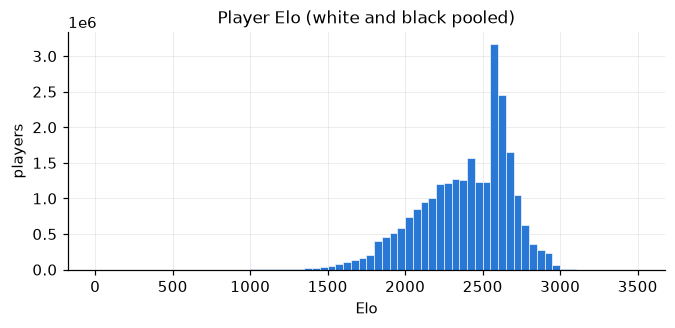

|white - black| Elo gap: median 99.0  90th pct 293.0
                        games  elo_missing     mean_elo  mean_plies
source                                                             
LichessEliteDatabase  5525245        0.000  2617.261963      89.920
LumbrasGigaBase       3701341        0.253  2102.266113      76.659
PGNMentor             3431537        0.135  2292.927002      81.763
TWIC                   858163        0.027  2233.649902      85.442
Masters                322166        0.207  2289.864014      77.505
LichessBroadcast       105329        0.092  2088.739990      85.171
ChessOK                 62895        0.065  2141.176025      80.271
Britbase                60148        0.313  2099.477051      75.519
Kingbase                59317        0.000  2305.017090      77.952
Convekta                37536        0.400  2070.419922      76.275
ChessNostalgia          24592        0.602  2355.444092      76.467
Chessopolis               123        0.748  2377.677979      71

In [8]:
elo = pd.concat([games["white_elo"], games["black_elo"]]).dropna()
elo = elo[(elo > 0) & (elo < 3500)]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(elo, bins=np.arange(0, 3501, 50), color=BLUE, edgecolor="white", linewidth=0.4)
ax.set_title("Player Elo (white and black pooled)"); ax.set_xlabel("Elo"); ax.set_ylabel("players")
plt.show()

gap = (games.loc[both, "white_elo"] - games.loc[both, "black_elo"])
print("|white - black| Elo gap: median", gap.abs().median(), " 90th pct", gap.abs().quantile(0.9))

by_src = games.assign(mean_elo=games[["white_elo", "black_elo"]].mean(axis=1)).groupby("source", observed=True).agg(
    games=("n_plies", "size"),
    elo_missing=("white_elo", lambda s: s.isna().mean()),
    mean_elo=("mean_elo", "mean"),
    mean_plies=("n_plies", "mean")).round(3)
print(by_src.sort_values("games", ascending=False).to_string())

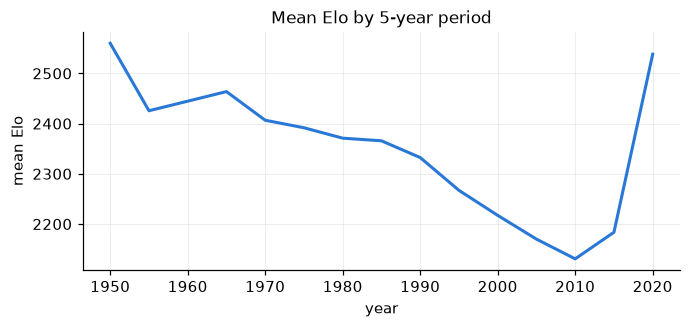

In [9]:
yr = games.assign(mean_elo=games[["white_elo", "black_elo"]].mean(axis=1)).dropna(subset=["year", "mean_elo"])
yr = yr[yr.year >= 1950].groupby((yr.year // 5 * 5).astype(int))["mean_elo"].mean()
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(yr.index, yr.values, color=BLUE, lw=2)
ax.set_title("Mean Elo by 5-year period"); ax.set_xlabel("year"); ax.set_ylabel("mean Elo")
plt.show()

w              black   draw  white
gap                               
(-2000, -400]  0.806  0.110  0.084
(-400, -200]   0.639  0.209  0.152
(-200, -100]   0.516  0.241  0.242
(-100, -50]    0.427  0.262  0.312
(-50, 0]       0.367  0.264  0.369
(0, 50]        0.311  0.256  0.433
(50, 100]      0.257  0.236  0.507
(100, 200]     0.194  0.206  0.601
(200, 400]     0.116  0.165  0.719
(400, 2000]    0.065  0.084  0.851


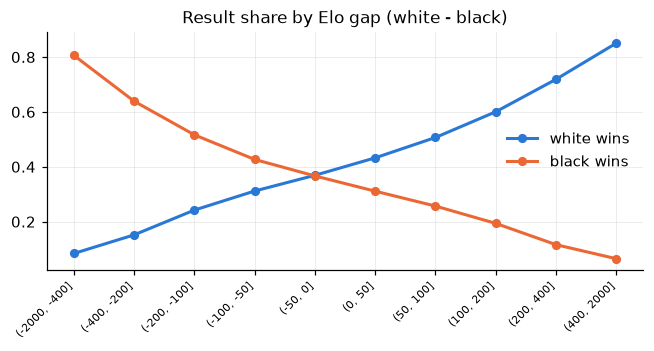

In [10]:
# Is the Elo gap informative? Share of results by white-minus-black Elo gap.
edges = [-2000, -400, -200, -100, -50, 0, 50, 100, 200, 400, 2000]
g = pd.DataFrame({"gap": pd.cut(gap, edges), "w": games.loc[both, "winner"].astype(object).fillna("draw")})
tab = pd.crosstab(g["gap"], g["w"], normalize="index")
print(tab.round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(range(len(tab)), tab["white"].values, color=BLUE, lw=2, marker="o", ms=5, label="white wins")
ax.plot(range(len(tab)), tab["black"].values, color=ORANGE, lw=2, marker="o", ms=5, label="black wins")
ax.set_xticks(range(len(tab))); ax.set_xticklabels([str(i) for i in tab.index], rotation=45, ha="right", fontsize=7)
ax.set_title("Result share by Elo gap (white - black)"); ax.legend(frameon=False)
plt.show()

### Elo groups
Quantile-based edges give seven groups of roughly equal size. Replace `EDGES` with the Zhong et al. boundaries if we adopt them.

In [11]:
mean_elo = games.loc[both, ["white_elo", "black_elo"]].mean(axis=1)
mean_elo = mean_elo[(mean_elo > 0) & (mean_elo < 3500)]
EDGES = sorted(set(float(x) for x in np.round(mean_elo.quantile(np.linspace(0, 1, 8)).values, 0)))
EDGES[0], EDGES[-1] = 0, 4000
grp = pd.cut(mean_elo, EDGES, right=False)
print("edges:", EDGES)
print(grp.value_counts().sort_index().to_string())

edges: [0, 2070.0, 2250.0, 2386.0, 2510.0, 2598.0, 2666.0, 4000]
[0.0, 2070.0)       1733022
[2070.0, 2250.0)    1740797
[2250.0, 2386.0)    1729353
[2386.0, 2510.0)    1737652
[2510.0, 2598.0)    1724222
[2598.0, 2666.0)    1755113
[2666.0, 4000.0)    1727087


## 5. Game length

count    14188454.0
mean           83.7
std            37.4
min            11.0
1%             20.0
5%             34.0
25%            58.0
50%            78.0
75%           104.0
95%           149.0
99%           198.0
max           692.0
under 10 plies: 0.00%   over 200 plies: 0.94%


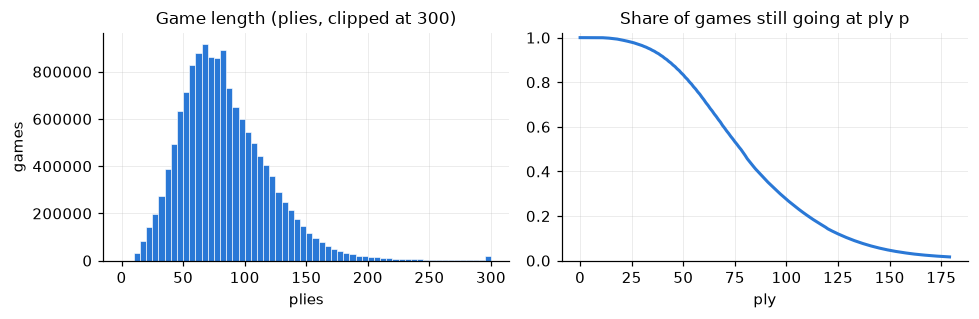

training positions (every ply is one example): 1,187,379,898


In [12]:
L = games["n_plies"].astype(int)
print(L.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_string())
print("under 10 plies:", f"{(L < 10).mean():.2%}", "  over 200 plies:", f"{(L > 200).mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(L.clip(upper=300), bins=np.arange(0, 301, 5), color=BLUE, edgecolor="white", linewidth=0.4)
axes[0].set(title="Game length (plies, clipped at 300)", xlabel="plies", ylabel="games")
surv = [(L > p).mean() for p in range(MAX_PLY * 3)]
axes[1].plot(range(len(surv)), surv, color=BLUE, lw=2)
axes[1].set(title="Share of games still going at ply p", xlabel="ply", ylim=(0, 1.02))
plt.tight_layout(); plt.show()

TOTAL_POSITIONS = int(L.sum())
print(f"training positions (every ply is one example): {TOTAL_POSITIONS:,}")

## 6. Duplicates
The sources overlap (for example TWIC, PGNMentor and Lichess Elite can contain the same games). Duplicates must stay inside one split, or test accuracy will be inflated. Games are matched on the full move list. Very short games match by chance, so the long-game figure is the useful one.

In [13]:
if not EXACT:
    print("NOTE: this is a sample, so duplicates across the full file are undercounted. Use STEP = 1.")
dup = games["h"].duplicated(keep=False)
print(f"games whose move list appears more than once: {dup.sum():,} ({dup.mean():.2%})")
long_ = L >= 20
print(f"same, for games with >= 20 plies:             {(dup & long_).sum():,} ({(dup & long_).sum()/long_.sum():.2%})")
print(f"unique move lists (>= 20 plies): {games.loc[long_, 'h'].nunique():,}")

d = games.loc[dup & long_, ["h", "source"]]
span = d.groupby("h", observed=True)["source"].nunique()
print(f"duplicated groups spanning more than one source: {(span > 1).sum():,} of {len(span):,}")

games whose move list appears more than once: 171,748 (1.21%)
same, for games with >= 20 plies:             162,747 (1.16%)


## 7. The target: move classes
Each move (e.g. `e2e4`) is one class. The top-1 share is the accuracy of always guessing the single most common move.

In [ ]:
mc = pd.Series(move_counts).sort_values(ascending=False)
total_moves = int(mc.sum())
share = mc / total_moves
cum = share.cumsum()

print(f"distinct moves: {len(mc):,}   total moves: {total_moves:,}   promotions: {promo_total:,}")
print(f"most common move: {mc.index[0]} = {share.iloc[0]:.2%}  (accuracy of always guessing it)")
for k in (10, 50, 100, 500, 1000):
    print(f"top {k:>4} moves cover {cum.iloc[min(k, len(cum))-1]:.1%} of all moves")
for lim in (10, 100, 1000):
    print(f"moves seen < {lim:>4} times: {(mc < lim).sum():,}")
print(f"entropy of the move distribution: {-(share * np.log2(share)).sum():.2f} bits (max {np.log2(len(mc)):.2f})")
print(); print(share.head(20).round(4).to_string())

distinct moves: 1,968   total moves: 1,187,379,898   promotions: 1,902,677
most common move: g8f6 = 1.06%  (accuracy of always guessing it)
top   10 moves cover 9.0% of all moves
top   50 moves cover 26.0% of all moves
top  100 moves cover 37.9% of all moves
top  500 moves cover 76.2% of all moves
top 1000 moves cover 91.5% of all moves
moves seen <   10 times: 4
moves seen <  100 times: 64
moves seen < 1000 times: 115
entropy of the move distribution: 9.66 bits (max 10.94)

g8f6    0.0106
g1f3    0.0105
d2d4    0.0102
e8g8    0.0096
e1g1    0.0094
b1c3    0.0089
e2e4    0.0087
e7e6    0.0077
b8c6    0.0072
g7g6    0.0069
c7c5    0.0066
c2c4    0.0065
d7d5    0.0065
d7d6    0.0060
g2g3    0.0057
a7a6    0.0055
h2h3    0.0052
f8e7    0.0052
h7h6    0.0051
c7c6    0.0048


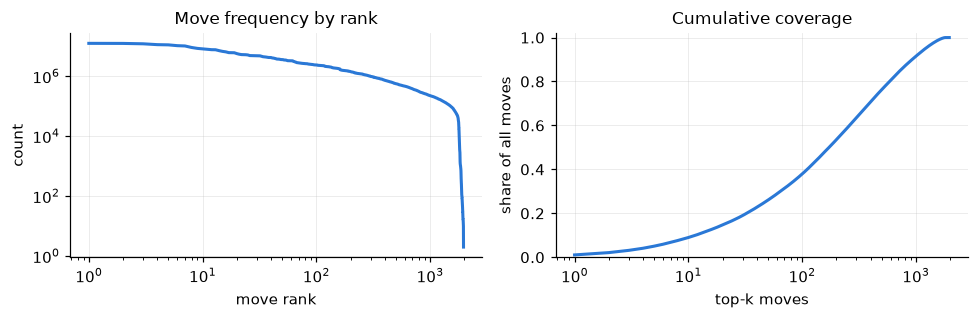

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(np.arange(1, len(mc) + 1), mc.values, color=BLUE, lw=2)
axes[0].set(xscale="log", yscale="log", xlabel="move rank", ylabel="count", title="Move frequency by rank")
axes[1].plot(np.arange(1, len(cum) + 1), cum.values, color=BLUE, lw=2)
axes[1].set(xscale="log", ylim=(0, 1.02), xlabel="top-k moves", ylabel="share of all moves", title="Cumulative coverage")
plt.tight_layout(); plt.show()

## 8. Move choice by ply
Ply 0 is White's first move, ply 1 is Black's first reply, and so on. How predictable is a move given only its position in the game? The table below is the accuracy of the "most-frequent move at each ply" lookup. It is the weakest sensible baseline, and the n-gram models have to beat it. (In-sample here, since it only measures how concentrated the moves are.)

In [ ]:
pc_ = pd.Series(ply_counts)
pc_.index = pd.MultiIndex.from_tuples(pc_.index, names=["ply", "move"])
pc_ = pc_.rename("n").reset_index()

rows = []
for ply, d in pc_.groupby("ply"):
    n = d["n"].sum(); p = d["n"] / n; top = d.loc[d["n"].idxmax()]
    rows.append({"ply": ply, "positions": n, "distinct_moves": len(d), "top_move": top["move"],
                 "top_share": top["n"] / n, "entropy_bits": float(-(p * np.log2(p)).sum())})
per_ply = pd.DataFrame(rows).set_index("ply")
print(per_ply.head(12).round(3).to_string())

w = per_ply["positions"]
print(f"\nmost-frequent-move-per-ply accuracy over the first {MAX_PLY} plies: {(per_ply.top_share * w).sum() / w.sum():.2%}")

     positions  distinct_moves top_move  top_share  entropy_bits
ply                                                             
0     14188454              21     e2e4      0.478         1.874
1     14188454              21     g8f6      0.259         2.874
2     14188454             105     g1f3      0.343         2.992
3     14188454             118     e7e6      0.163         3.595
4     14188454             377     b1c3      0.203         4.141
5     14188454             415     g8f6      0.134         4.718
6     14188454             623     f3d4      0.103         5.085
7     14188454             716     g8f6      0.170         5.151
8     14188454             818     b1c3      0.123         5.472
9     14188454             902     e8g8      0.093         5.588
10    14188454            1043     e1g1      0.078         5.935
11    14181944            1123     e8g8      0.071         5.937

most-frequent-move-per-ply accuracy over the first 60 plies: 6.43%


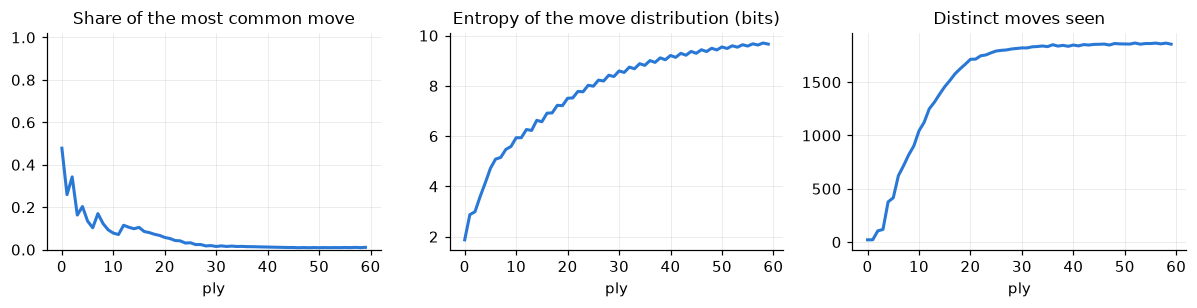

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.9))
axes[0].plot(per_ply.index, per_ply["top_share"], color=BLUE, lw=2)
axes[0].set(title="Share of the most common move", xlabel="ply", ylim=(0, 1.02))
axes[1].plot(per_ply.index, per_ply["entropy_bits"], color=BLUE, lw=2)
axes[1].set(title="Entropy of the move distribution (bits)", xlabel="ply")
axes[2].plot(per_ply.index, per_ply["distinct_moves"], color=BLUE, lw=2)
axes[2].set(title="Distinct moves seen", xlabel="ply")
plt.tight_layout(); plt.show()

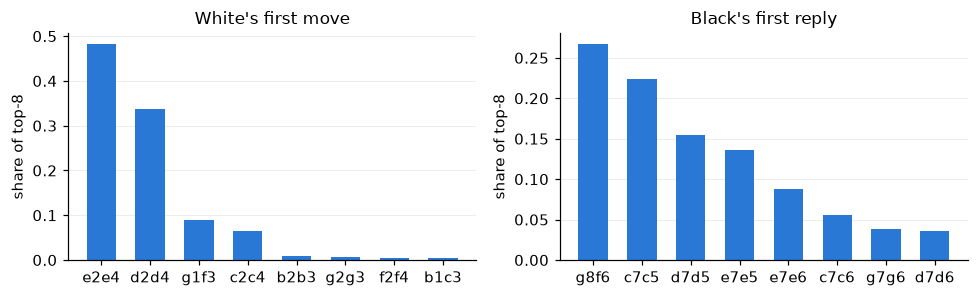

In [ ]:
first = pc_[pc_.ply == 0].sort_values("n", ascending=False).head(8)
reply = pc_[pc_.ply == 1].sort_values("n", ascending=False).head(8)
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
for ax, d, title in zip(axes, (first, reply), ("White's first move", "Black's first reply")):
    ax.bar(d["move"], d["n"] / d["n"].sum() * (1), color=BLUE, width=0.6)
    ax.set_title(title); ax.set_ylabel("share of top-8"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 9. Split planning
Split by game, not by position, and keep duplicates together. A deterministic hash split does both.

In [ ]:
bucket = (games["h"] % 100).astype(int)
split = np.where(bucket < 80, "train", np.where(bucket < 90, "val", "test"))
s = pd.DataFrame({"split": split, "n_plies": L}).groupby("split").agg(games=("n_plies", "size"), positions=("n_plies", "sum"))
print(s.to_string())

          games  positions
split                     
test    1416535  118432571
train  11353729  950251491
val     1418190  118695836


## 10. Dataset summary (for the report)

In [ ]:
print(f"""
Games in file (exact):          {TOTAL_GAMES:,}
Games analysed:                 {len(games):,}{'' if EXACT else '  [SAMPLE: set STEP = 1 for exact numbers]'}
Games with both Elo present:    {both.mean():.1%}
Mean / median game length:      {L.mean():.1f} / {L.median():.0f} plies
Training positions (examples):  {TOTAL_POSITIONS:,}
Duplicate games (>= 20 plies):  {(dup & long_).sum()/long_.sum():.2%}

Problem:   classification (next move, UCI string, e.g. e2e4)
Classes:   {len(mc):,} distinct moves
Balance:   NOT balanced. Top move = {share.iloc[0]:.1%}; top 50 moves cover {cum.iloc[49]:.1%}
Features:  white Elo, black Elo, ply number, previous moves (history so far)
Target:    the move played at the next ply
""")


Games in file (exact):          14,188,454
Games analysed:                 14,188,454
Games with both Elo present:    85.6%
Mean / median game length:      83.7 / 78 plies
Training positions (examples):  1,187,379,898
Duplicate games (>= 20 plies):  1.16%

Problem:   classification (next move, UCI string, e.g. e2e4)
Classes:   1,968 distinct moves
Balance:   NOT balanced. Top move = 1.1%; top 50 moves cover 26.0%
Features:  white Elo, black Elo, ply number, previous moves (history so far)
Target:    the move played at the next ply

